# 05 Explain

This notebook explains the model the hook uses, `xgboost_no_value_empty` from `04_models`, on the test set. It uses SHAP to show which features drive its scores, looks at a few single rows, and then studies where it fails: false alarms on F rows against X rows, and errors by file type and by words in the path.

Only the saved model file and the saved feature tables are used, so the scores here are exactly the ones reported in `04_models` and the ones the hook produces. Outputs show ids, counts, scores and feature values only, never `LineText` or `Value`, because the notebook is tracked by git.

## Setup

We import the libraries and set the paths. The notebook runs from the `notebooks` folder, so paths go up one level.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

DATA_DIR = Path("..") / "data" / "processed"
MODEL_PATH = Path("..") / "models" / "gitguard_model.joblib"
ID_COLS = ["Id", "RepoId", "GroundTruth", "label"]
SEED = 65

## Load the model and the test set

We load the model file and the scaled test table, score the test rows with the model, and check that the scores match the ones `04_models` saved in `test_scores.csv`. Each row then gets an outcome: a real secret that is found (TP) or missed (FN), and a false alarm on an F row or an X row, or a correct pass (TN).

In [2]:
bundle = joblib.load(MODEL_PATH)
model, features, threshold = bundle["model"], bundle["features"], bundle["threshold"]

test = pd.read_csv(DATA_DIR / "features_test.csv", dtype=str, keep_default_na=False)
saved = pd.read_csv(DATA_DIR / "test_scores.csv", dtype=str, keep_default_na=False)
X = test[features].astype(float)
y = test["label"].astype(int).to_numpy()
gt = test["GroundTruth"].to_numpy()

score = model.predict_proba(X)[:, 1]
same = np.allclose(score, saved.set_index("Id").loc[test["Id"], bundle["name"]].astype(float).to_numpy(), atol=1e-6)
flagged = score >= threshold

outcome = np.select(
    [flagged & (y == 1), ~flagged & (y == 1), flagged & (gt == "F"), flagged & (gt == "X")],
    ["TP", "FN", "FP_F", "FP_X"],
    default="TN",
)
print(bundle["name"], "| threshold", round(threshold, 4), "| scores match test_scores.csv:", same)
print(pd.Series(outcome).value_counts().reindex(["TP", "FN", "FP_F", "FP_X", "TN"]).to_string())

xgboost_no_value_empty | threshold 0.4158 | scores match test_scores.csv: True
TP      2859
FN       219
FP_F     291
FP_X     188
TN      9678


The scores match `test_scores.csv`, so this is the same model and the same test result as in `04_models`: 2,859 real secrets found and 219 missed, 291 false alarms on F rows and 188 on X rows, and 9,678 correct passes.

## SHAP values

SHAP splits each score into one contribution per feature, so that the base value plus all contributions gives the model output for that row, on the log odds scale. `TreeExplainer` computes exact values for tree models. It takes about half a minute on all test rows, so no sample is needed, and we check that the contributions add up to the model output.

In [3]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)
margin = model.predict(X, output_margin=True)
gap = np.abs(margin - (explainer.expected_value + shap_values.sum(axis=1))).max()
print("SHAP values:", shap_values.shape, "| base value", round(float(explainer.expected_value), 4))
print("largest gap between model output and base value plus contributions:", float(gap))

SHAP values: (13235, 38) | base value 0.0032
largest gap between model output and base value plus contributions: 1.52587890625e-05


The contributions add up to the model output to within 0.00002 on every row, so the SHAP values are exact. The base value is close to 0 on the log odds scale, that is a score near 0.5, because `scale_pos_weight` balances the two classes in training.

## Summary plot

Each dot is one test row. The position shows how much the feature pushed that row toward a real secret (right) or a false alarm (left), and the colour shows whether the feature value was high or low. Features are sorted by their mean absolute contribution.

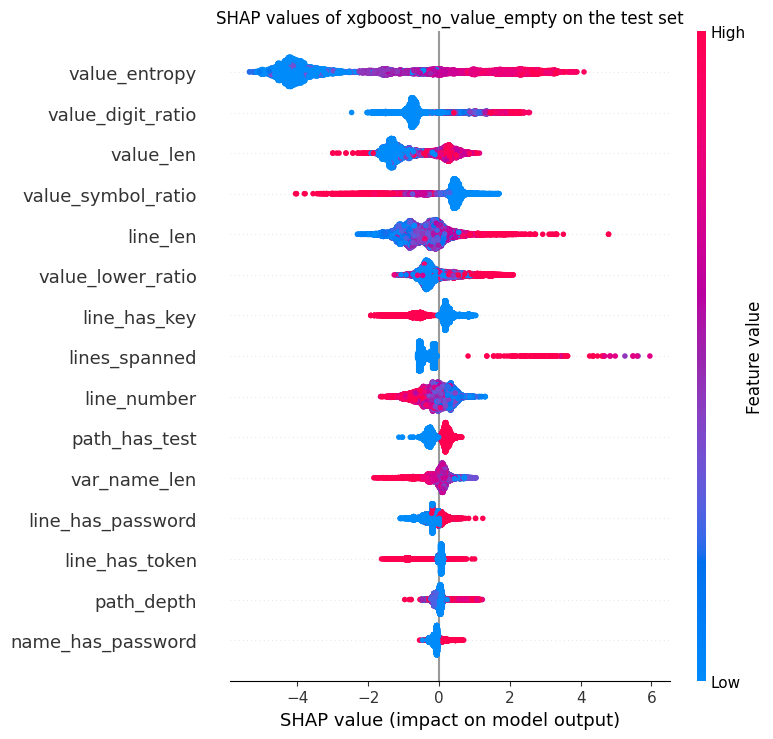

In [4]:
shap.summary_plot(shap_values, X, max_display=15, show=False)
plt.title("SHAP values of xgboost_no_value_empty on the test set")
plt.tight_layout()
plt.show()

`value_entropy` dominates: high entropy pushes rows strongly toward a real secret and low entropy strongly away from it. Most of the next features also describe the value: its digit share, length and symbol share. The table below gives the numbers.

## Mean contribution and direction

The plot is easier to quote as a table. For each feature we give the mean absolute SHAP value, its share of the total, and the Spearman correlation between the feature value and its SHAP value. A positive correlation means that higher values push toward a real secret.

In [5]:
def direction(i, f):
    # A feature with one value, or one the model never uses, has no direction
    if X[f].nunique() < 2 or np.all(shap_values[:, i] == shap_values[0, i]):
        return np.nan
    return pd.Series(X[f]).corr(pd.Series(shap_values[:, i]), method="spearman")


mean_abs = np.abs(shap_values).mean(axis=0)
importance = pd.DataFrame({
    "mean_abs_shap": mean_abs,
    "share_percent": mean_abs / mean_abs.sum() * 100,
    "direction": [direction(i, f) for i, f in enumerate(features)],
}, index=features).sort_values("mean_abs_shap", ascending=False)
print("features with one value on the test set:", [f for f in features if X[f].nunique() < 2])
print("features the model never uses on the test set:", [f for i, f in enumerate(features) if np.all(shap_values[:, i] == 0)])
print(importance.head(15).round(3).to_string())
print()
print("top 5 features hold", round(importance["share_percent"].head(5).sum(), 2), "percent of the total")

features with one value on the test set: []
features the model never uses on the test set: ['multi_line']
                    mean_abs_shap  share_percent  direction
value_entropy               2.911         29.879      0.874
value_digit_ratio           0.903          9.270      0.718
value_len                   0.857          8.802      0.752
value_symbol_ratio          0.609          6.247     -0.696
line_len                    0.600          6.155      0.535
value_lower_ratio           0.428          4.393      0.600
line_has_key                0.424          4.351     -0.807
lines_spanned               0.404          4.145      0.183
line_number                 0.339          3.484     -0.804
path_has_test               0.241          2.472      0.861
var_name_len                0.231          2.372     -0.687
line_has_password           0.215          2.207      0.669
line_has_token              0.172          1.762     -0.577
path_depth                  0.131          1.349     -

`value_entropy` alone holds 29.88 percent of the total contribution, and the five largest features hold 60.35 percent. Four of those five describe the value, so the model mostly judges how random the value looks, which is what `02_eda` found separates real secrets best. The directions match `02_eda`: more entropy, digits and length push toward a real secret, more symbols push away (minus 0.696), and a test path pushes toward a real secret (0.861), because test folders hold many real secrets in CredData. `line_has_key` pushes away from a real secret (minus 0.807), like in logistic regression. `multi_line` is never used, because `lines_spanned` carries the same information, while logistic regression gave `multi_line` its largest weight.

## Single rows

One row of each outcome, picked at random with a fixed seed, with its score and the five features that contributed most to it. Feature values are the scaled values the model sees, so for the numeric features 0 is the train mean and 1 is one standard deviation.

In [6]:
rng = np.random.default_rng(SEED)
for kind in ["TP", "FN", "FP_F", "FP_X"]:
    i = int(rng.choice(np.flatnonzero(outcome == kind)))
    top = np.argsort(-np.abs(shap_values[i]))[:5]
    print(f"{kind} | Id {test['Id'].iloc[i]} | GroundTruth {gt[i]} | score {score[i]:.4f}")
    for j in top:
        print(f"    {features[j]:<22} value {X.iloc[i, j]:>8.3f}   contribution {shap_values[i, j]:>+8.3f}")
    print()

TP | Id 1493544 | GroundTruth T | score 0.9984
    value_entropy          value    1.588   contribution   +3.210
    value_digit_ratio      value    0.216   contribution   +1.084
    path_depth             value    3.446   contribution   +0.961
    value_upper_ratio      value    1.351   contribution   +0.662
    value_symbol_ratio     value   -0.435   contribution   +0.593

FN | Id 35850 | GroundTruth T | score 0.3772
    value_lower_ratio      value    2.313   contribution   +1.151
    path_depth             value    2.406   contribution   -0.795
    value_len              value    0.489   contribution   -0.681
    value_digit_ratio      value   -0.603   contribution   -0.660
    value_symbol_ratio     value   -0.435   contribution   +0.600

FP_F | Id 11529344 | GroundTruth F | score 0.5041
    value_symbol_ratio     value   -0.435   contribution   +0.971
    line_has_key           value    1.000   contribution   -0.608
    value_entropy          value    0.531   contribution   -0.55

The found secret is carried by its high entropy (plus 3.21). The missed secret scores 0.377, just under the threshold of 0.416, because its value is short and has few digits. The F false alarm scores 0.504 mostly because its value has no symbols. The X false alarm scores 0.421, just over the threshold: its low entropy pushes it down (minus 2.41), but its all lower case value and its early line number push it back up. Single rows are only examples, and the group tables below are the evidence.

## False alarms on F rows and on X rows

`02_eda` found that F and X differ: X values are short test or example values, often in test paths and named like passwords. Here we compare the false alarms of each kind with the real secrets that are found. The value length and entropy are turned back into their original units with `scaler_params.csv` so they can be read directly.

In [7]:
params = pd.read_csv(DATA_DIR / "scaler_params.csv", dtype=str, keep_default_na=False).set_index("feature")


def original_units(column):
    # Undoes the scaling and the log transform of one numeric feature
    p = params.loc[column]
    values = test[column].astype(float) * float(p["scale"]) + float(p["mean"])
    return np.expm1(values) if p["log1p"] == "True" else values


value_len = original_units("value_len")
value_entropy = original_units("value_entropy")
groups = {"TP": outcome == "TP", "FP_F": outcome == "FP_F", "FP_X": outcome == "FP_X", "TN": outcome == "TN"}
rows = []
for name, mask in groups.items():
    rows.append({
        "outcome": name,
        "rows": int(mask.sum()),
        "median_score": round(float(np.median(score[mask])), 4),
        "median_value_len": round(float(value_len[mask].median()), 1),
        "median_value_entropy": round(float(value_entropy[mask].median()), 3),
        "value_empty_percent": round(test.loc[mask, "value_empty"].astype(float).mean() * 100, 2),
        "path_has_test_percent": round(test.loc[mask, "path_has_test"].astype(float).mean() * 100, 2),
        "name_has_password_percent": round(test.loc[mask, "name_has_password"].astype(float).mean() * 100, 2),
    })
print(pd.DataFrame(rows).to_string(index=False))

outcome  rows  median_score  median_value_len  median_value_entropy  value_empty_percent  path_has_test_percent  name_has_password_percent
     TP  2859        0.9835              36.0                 3.740                 4.09                  66.77                      20.32
   FP_F   291        0.7817              12.0                 3.182                12.71                  67.70                      25.09
   FP_X   188        0.6624               8.0                 2.750                 0.00                  77.13                      64.36
     TN  9678        0.0004               0.0                 0.000                72.02                  48.93                      14.90


The false alarms sit between the real secrets and the correct passes. Real secrets found have a median value length of 36 and entropy of 3.74. F false alarms have shorter values (median 12, entropy 3.18), and 12.71 percent of them have no annotated value. X false alarms have the shortest values (median 8, entropy 2.75), always have a value, sit in a test path 77.13 percent of the time and have password in the variable name 64.36 percent of the time, against 20.32 percent for real secrets found. So X false alarms look like test passwords: short, readable and named like a password.

For each kind of false alarm, which features pushed it over the threshold? We compare the mean SHAP value per feature in each group and show the features with the largest mean push toward a real secret among F and X false alarms.

In [8]:
mean_shap = pd.DataFrame({name: shap_values[mask].mean(axis=0) for name, mask in groups.items()}, index=features)
for name in ["FP_F", "FP_X"]:
    print("largest mean push toward a real secret,", name)
    print(mean_shap.sort_values(name, ascending=False)[[name, "TP", "TN"]].head(6).round(3).to_string())
    print()

largest mean push toward a real secret, FP_F
                      FP_F     TP     TN
value_entropy        0.494  1.629 -3.197
lines_spanned        0.265 -0.015 -0.454
value_lower_ratio    0.252  0.403 -0.212
value_digit_ratio    0.243  0.955 -0.738
line_len             0.125 -0.029 -0.532
line_has_key_header  0.104  0.044 -0.072

largest mean push toward a real secret, FP_X
                     FP_X     TP     TN
value_lower_ratio   0.821  0.403 -0.212
value_symbol_ratio  0.267  0.160  0.201
line_has_key        0.256  0.304 -0.157
value_len           0.227  0.210 -0.968
line_has_password   0.188  0.046 -0.181
line_number         0.134  0.004 -0.128



F false alarms are pushed over the threshold mostly by entropy that is higher than for the correct passes (plus 0.494 against minus 3.197 on average), so these are values that look somewhat random. X false alarms are pushed mostly by `value_lower_ratio` (plus 0.821, twice its mean push on real secrets) and by `line_has_password` (plus 0.188 against 0.046 on real secrets). The model has learned that a value of lower case letters next to a password keyword can be a real secret, and test passwords match that pattern.

## Errors by file type

`src/features.py` groups file extensions into code, config, script, doc, keyfile, none and other, and each row has exactly one of these flags. For each group we give the number of rows, the recall on real secrets, the share of non secrets flagged, and the precision.

In [9]:
def error_table(masks):
    # Recall, false alarm rate and precision for each named group of test rows
    out = []
    for name, mask in masks.items():
        pos, neg = mask & (y == 1), mask & (y == 0)
        out.append({
            "group": name,
            "rows": int(mask.sum()),
            "real_secrets": int(pos.sum()),
            "recall": round(flagged[pos].mean(), 4) if pos.any() else np.nan,
            "false_alarm_rate": round(flagged[neg].mean(), 4) if neg.any() else np.nan,
            "precision": round(y[mask & flagged].mean(), 4) if (mask & flagged).any() else np.nan,
        })
    return pd.DataFrame(out)


ext_cols = [c for c in test.columns if c.startswith("ext_")]
print("rows with exactly one extension group:", int((test[ext_cols].astype(float).sum(axis=1) == 1).sum()), "of", len(test))
ext_masks = {c.replace("ext_", ""): test[c].astype(float).to_numpy() == 1 for c in ext_cols}
print(error_table(ext_masks).sort_values("rows", ascending=False).to_string(index=False))

rows with exactly one extension group: 13235 of 13235
  group  rows  real_secrets  recall  false_alarm_rate  precision
   code  7124          1415  0.9081            0.0466     0.8285
 config  2475          1171  0.9667            0.0637     0.9317
  other  1926           256  0.8789            0.0347     0.7951
    doc  1056           149  0.8859            0.0584     0.7135
 script   429            23  0.9565            0.0197     0.7333
   none   163            14  0.9286            0.0067     0.9286
keyfile    62            50  1.0000            0.8333     0.8333


Every test row has exactly one extension group. Config files are handled best (recall 0.9667, precision 0.9317). The `other` group has the lowest recall (0.8789), and doc files have the lowest precision of the large groups (0.7135), so text and documentation files cause the most false alarms per alarm raised. Key files are found every time, but 10 of their 12 non secret rows are flagged too (false alarm rate 0.8333), because the model treats key material as a real secret almost by default. With 62 rows this group is too small for firm conclusions.

## Errors by words in the path

The same measures for rows whose path contains a test, example, mock or doc word, and for rows with none of them. A row can have more than one of these words, so the first four groups overlap.

In [10]:
path_cols = ["path_has_test", "path_has_example", "path_has_mock", "path_has_doc"]
path_flags = test[path_cols].astype(float).to_numpy() == 1
path_masks = {c.replace("path_has_", ""): path_flags[:, k] for k, c in enumerate(path_cols)}
path_masks["none of these"] = ~path_flags.any(axis=1)
path_masks["all test rows"] = np.ones(len(test), dtype=bool)
print(error_table(path_masks).to_string(index=False))

        group  rows  real_secrets  recall  false_alarm_rate  precision
         test  7135          2058  0.9276            0.0674     0.8481
      example  2088           727  0.9450            0.0206     0.9608
         mock   918           405  0.9407            0.0624     0.9225
          doc   815           124  0.9194            0.0347     0.8261
none of these  4468           445  0.9371            0.0249     0.8066
all test rows 13235          3078  0.9288            0.0472     0.8565


Recall is similar in every path group (0.919 to 0.945), so the model does not miss secrets in test or example folders. Test paths have the highest false alarm rate (0.0674), more than twice the rate for paths with none of these words (0.0249), which fits the X false alarms above. Rows in example folders get the highest precision (0.9608).

## Errors by repository

Errors may come from a few repositories rather than being spread evenly. We count missed secrets and false alarms per test repository and show how much of each the five worst repositories hold.

In [11]:
repo = test["RepoId"].to_numpy()
for kind, mask in [("missed secrets (FN)", outcome == "FN"), ("false alarms (FP_F and FP_X)", np.isin(outcome, ["FP_F", "FP_X"]))]:
    counts = pd.Series(repo[mask]).value_counts()
    print(kind, "| total", int(mask.sum()), "| repositories with at least one:", len(counts),
          "| five largest hold", round(counts.head(5).sum() / mask.sum() * 100, 2), "percent")
    print("   ", counts.head(5).to_dict())

missed secrets (FN) | total 219 | repositories with at least one: 28 | five largest hold 71.69 percent
    {'6c73b80a': 74, 'e08ff555': 33, 'a09d9e50': 26, 'f710ac3c': 13, 'a15774b8': 11}
false alarms (FP_F and FP_X) | total 479 | repositories with at least one: 50 | five largest hold 50.73 percent
    {'f710ac3c': 88, '387016a6': 76, 'a09d9e50': 28, '894e3377': 28, '288eaba8': 23}


Errors are concentrated. The 219 missed secrets come from only 28 of the 67 test repositories, the five worst hold 71.69 percent of them, and one repository alone holds 74 (33.8 percent). The 479 false alarms come from 50 repositories, and the five worst hold 50.73 percent. A few repositories with unusual secrets or many test values therefore decide much of the error rate, which also explains why scores varied so much between folds in `04_models`.